# Breast Cancer Image Classification with BreakHis

## Project overview
This notebook explores binary classification of breast histopathology images as **benign** or **malignant** using the BreakHis dataset. It compares a small CNN built from scratch with a pretrained ResNet18 model.

**Important:** This is an educational machine-learning experiment, not a diagnostic tool. The dataset split, evaluation design, and results need further validation before making any clinical claims.

### Workflow
1. Download and inspect the dataset.
2. Build an image metadata index.
3. Create patient-wise train, validation, and test splits.
4. Train a baseline CNN.
5. Fine-tune ResNet18 and compare evaluation metrics.
6. Review limitations and possible data leakage.

## 1. Setup and dataset download

Download the BreakHis archive, mount Google Drive, extract the images, and confirm that image files are present.

In [1]:
!wget -O /content/BreaKHis_v1.tar.gz http://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz
!ls -lh /content/BreaKHis_v1.tar.gz

from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/BreakHis
!cp /content/BreaKHis_v1.tar.gz /content/drive/MyDrive/BreakHis/
!ls -lh /content/drive/MyDrive/BreakHis/

!ls -l /content/BreaKHis_v1.tar.gz /content/drive/MyDrive/BreakHis/BreaKHis_v1.tar.gz

!mkdir -p /content/breakhis
!tar -xzf /content/BreaKHis_v1.tar.gz -C /content/breakhis

!find /content/breakhis -name "*.png" | wc -l

--2026-10-19 15:01:12--  http://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz
Resolving www.inf.ufpr.br (www.inf.ufpr.br)... 200.17.202.113, 2801:82:80ff:8001:216:ccff:feaa:79
Connecting to www.inf.ufpr.br (www.inf.ufpr.br)|200.17.202.113|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz [following]
--2026-10-19 15:01:13--  https://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz
Connecting to www.inf.ufpr.br (www.inf.ufpr.br)|200.17.202.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4273561758 (4.0G) [application/octet-stream]
Saving to: ‘/content/BreaKHis_v1.tar.gz’

/content/BreaKHis_v 100%[===================>]   3.98G  22.4MB/s    in 3m 15s  

2026-10-19 15:04:28 (20.9 MB/s) - ‘/content/BreaKHis_v1.tar.gz’ saved [4273561758/4273561758]

-rw-r--r-- 1 root root 4.0G Nov 17  2016 /content/BreaKHis_v1.tar.gz
Mounted at /content/drive
total 4.1G
-rw------- 

## 2. Build the image index and inspect labels

Parse image filenames into labels and metadata, then inspect class, subtype, magnification, and patient distributions.

In [2]:
import glob
paths = sorted(glob.glob('/content/breakhis/**/*.png', recursive=True))
print(len(paths))
for p in paths[:3]:
    print(p)

import re
import pandas as pd

pattern = re.compile(r'SOB_([BM])_([A-Z]+)-(\d+-[0-9A-Za-z]+)-(\d+)-(\d+)\.png')

rows = []
failed = []
for p in paths:
    name = p.split('/')[-1]
    m = pattern.fullmatch(name)
    if m is None:
        failed.append(name)
        continue
    rows.append({
        'path': p,
        'label': 'benign' if m.group(1) == 'B' else 'malignant',
        'subtype': m.group(2),
        'slide_id': m.group(3),
        'magnification': int(m.group(4)),
        'seq': int(m.group(5)),
    })

df = pd.DataFrame(rows)
print("parsed:", len(df), " failed:", len(failed))
print(failed[:5])
print(df.head())

print("Label counts:")
print(df['label'].value_counts())

print("\nMagnification counts:")
print(df['magnification'].value_counts().sort_index())

print("\nSubtype counts:")
print(df['subtype'].value_counts())

print("\nUnique slide_ids:", df['slide_id'].nunique())
print("Slide_ids per label:")
print(df.groupby('label')['slide_id'].nunique())

# har slide_id ka sirf ek hi label hona chahiye
check = df.groupby('slide_id')['label'].nunique()
print("\nSlide_ids with more than 1 label:", (check > 1).sum())

df['folder'] = df['path'].str.split('/').str[-3]

print("Unique folders:", df['folder'].nunique())
print(df.groupby('label')['folder'].nunique())

x = df.groupby('slide_id')['folder'].nunique()
print("\nslide_ids that appear in more than 1 folder:")
print(x[x > 1])

print(df[df['slide_id'] == '14-13412'][['folder', 'label', 'subtype']].drop_duplicates())

df['patient_id'] = df['folder']

print("\nUnique patient_id:", df['patient_id'].nunique())
print(df.groupby('label')['patient_id'].nunique())

# har patient ka sirf ek label hona chahiye
print("Patients with more than 1 label:", (df.groupby('patient_id')['label'].nunique() > 1).sum())

# ek patient ke andar kitni images hain
print(df.groupby('patient_id').size().describe())

df.to_csv('/content/drive/MyDrive/BreakHis/breakhis_index.csv', index=False)
print("saved", len(df), "rows")

7909
/content/breakhis/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-001.png
/content/breakhis/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-002.png
/content/breakhis/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-003.png
parsed: 7909  failed: 0
[]
                                                path   label subtype  \
0  /content/breakhis/BreaKHis_v1/histology_slides...  benign       A   
1  /content/breakhis/BreaKHis_v1/histology_slides...  benign       A   
2  /content/breakhis/BreaKHis_v1/histology_slides...  benign       A   
3  /content/breakhis/BreaKHis_v1/histology_slides...  benign       A   
4  /content/breakhis/BreaKHis_v1/histology_slides...  benign       A   

     slide_id  magnification  seq  
0  14-22549AB            100    1  
1  14-22549AB            100    2  
2  14-22549AB            100    3  
3  1

## 3. Visualize and validate the images

Display sample images, verify image readability, and inspect image dimensions.

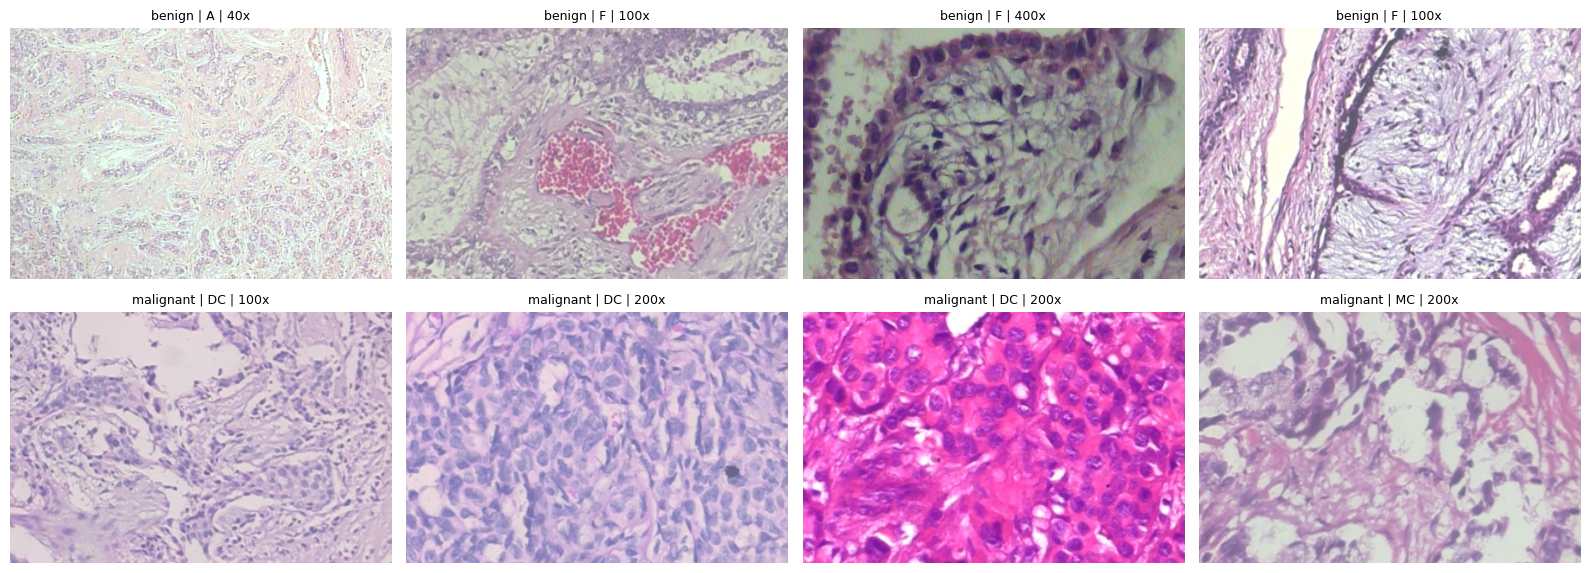

bad files: 0
sizes/modes found: {((700, 456), 'RGB'), ((700, 460), 'RGB')}
size
(700, 460)    7835
(700, 456)      74
Name: count, dtype: int64

700x456 by label:
label
malignant    74
Name: count, dtype: int64
700x456 by magnification:
magnification
100    21
40     21
200    19
400    13
Name: count, dtype: int64
Patients having 700x456 images: 1
total 4.1G
-rw------- 1 root root 1.6M Oct 19 15:15 breakhis_index.csv
-rw------- 1 root root 4.0G Oct 19 15:08 BreaKHis_v1.tar.gz
-rw------- 1 root root  43M Oct 19 12:44 resnet18_best.pt
-rw------- 1 root root  986 Oct 19 12:49 resnet18_history.csv
-rw------- 1 root root 397K Oct 19 12:24 simplecnn_best.pt
-rw------- 1 root root 1.2K Oct 19 12:33 simplecnn_history.csv
-rw------- 1 root root 1.4M Oct 19 13:25 split_grouped_seed42.csv


In [3]:
import matplotlib.pyplot as plt
from PIL import Image

sample = df.groupby('label').sample(4, random_state=0)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(r['path']))
    ax.set_title(f"{r['label']} | {r['subtype']} | {r['magnification']}x", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

from PIL import Image

bad = []
sizes = set()
for p in df['path']:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            sizes.add((im.size, im.mode))
    except Exception as e:
        bad.append((p, str(e)))

print("bad files:", len(bad))
print("sizes/modes found:", sizes)

def get_size(p):
    with Image.open(p) as im:
        return im.size

df['size'] = df['path'].apply(get_size)
print(df['size'].value_counts())

odd = df[df['size'] == (700, 456)]
print("\n700x456 by label:")
print(odd['label'].value_counts())
print("700x456 by magnification:")
print(odd['magnification'].value_counts())
print("Patients having 700x456 images:", odd['patient_id'].nunique())

!ls -lh /content/drive/MyDrive/BreakHis/

## 4. Patient-wise train/validation/test split

Split by patient rather than individual image to reduce the risk of images from one patient appearing in multiple sets.

In [4]:
from sklearn.model_selection import train_test_split

pat = df.groupby('patient_id')['label'].first().reset_index()

train_p, temp_p = train_test_split(pat, test_size=0.30, stratify=pat['label'], random_state=42)
val_p, test_p = train_test_split(temp_p, test_size=0.50, stratify=temp_p['label'], random_state=42)

split_map = {}
for name, d in [('train', train_p), ('val', val_p), ('test', test_p)]:
    for pid in d['patient_id']:
        split_map[pid] = name
df['split'] = df['patient_id'].map(split_map)

print("Patients per split:")
print(df.groupby('split')['patient_id'].nunique())
print("\nImages per split and label:")
print(df.groupby(['split', 'label']).size().unstack())

# leakage check: koi patient do sets mein nahi hona chahiye
s = {k: set(df[df['split'] == k]['patient_id']) for k in ['train', 'val', 'test']}
print("\nOverlap train&val:", len(s['train'] & s['val']))
print("Overlap train&test:", len(s['train'] & s['test']))
print("Overlap val&test:", len(s['val'] & s['test']))

print("\nOdd-size patient is in:", df[df['size'] == (700, 456)]['split'].unique())

df.to_csv('/content/drive/MyDrive/BreakHis/breakhis_index.csv', index=False)

chk = pd.read_csv('/content/drive/MyDrive/BreakHis/breakhis_index.csv')
print(chk.columns.tolist())
print(chk['split'].value_counts())

!nvidia-smi

Patients per split:
split
test     13
train    57
val      12
Name: patient_id, dtype: int64

Images per split and label:
label  benign  malignant
split                   
test      625        710
train    1597       3806
val       258        913

Overlap train&val: 0
Overlap train&test: 0
Overlap val&test: 0

Odd-size patient is in: ['train']
['path', 'label', 'subtype', 'slide_id', 'magnification', 'seq', 'folder', 'patient_id', 'size', 'split']
split
train    5403
test     1335
val      1171
Name: count, dtype: int64
/bin/bash: line 1: nvidia-smi: command not found


## 5. Reload data and check the runtime

Reload the index, verify paths, and check whether PyTorch can access a GPU.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/breakhis
!tar -xzf /content/drive/MyDrive/BreakHis/BreaKHis_v1.tar.gz -C /content/breakhis

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/BreakHis/breakhis_index.csv')
print(len(df))
print(df['split'].value_counts())
import os
print("first path exists:", os.path.exists(df['path'].iloc[0]))

import torch
print("torch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

from PIL import Image

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
7909
split
train    5403
test     1335
val      1171
Name: count, dtype: int64
first path exists: True
torch version: 2.11.0+cpu
GPU available: False


## 6. Create the PyTorch dataset and data loaders

Resize images, convert them to tensors, and prepare batches for training and evaluation.

In [6]:
from torch.utils.data import Dataset
import torchvision.transforms as T

class BreakHisDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row['path']).convert('RGB')
        img = self.transform(img)
        label = 1 if row['label'] == 'malignant' else 0
        return img, label

basic_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
])

train_df = df[df['split'] == 'train']
val_df   = df[df['split'] == 'val']
test_df  = df[df['split'] == 'test']

train_ds = BreakHisDataset(train_df, basic_tf)
val_ds   = BreakHisDataset(val_df, basic_tf)
test_ds  = BreakHisDataset(test_df, basic_tf)

print(len(train_ds), len(val_ds), len(test_ds))

x, y = train_ds[0]
print("image shape:", x.shape)
print("min/max pixel:", x.min().item(), x.max().item())
print("label:", y)

from torch.utils.data import DataLoader
import time

BATCH = 32

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

print("batches:", len(train_loader), len(val_loader), len(test_loader))

t = time.time()
xb, yb = next(iter(train_loader))
print("one batch loaded in", round(time.time() - t, 1), "seconds")
print("images:", xb.shape)
print("labels:", yb.shape, yb[:10].tolist())

import torch.nn as nn

5403 1171 1335
image shape: torch.Size([3, 224, 224])
min/max pixel: 0.364705890417099 0.9098039269447327
label: 0
batches: 169 37 42
one batch loaded in 2.1 seconds
images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32]) [1, 0, 0, 0, 1, 1, 0, 0, 1, 1]


## 7. Define the baseline CNN

Build a small convolutional neural network and check its output shape.

In [9]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            block(3, 16),
            block(16, 32),
            block(32, 64),
            block(64, 128),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(128, 2)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.flatten(1)
        return self.classifier(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleCNN().to(device)

n_params = sum(p.numel() for p in model.parameters())
print("parameters:", n_params)

xb, yb = next(iter(train_loader))
with torch.no_grad():
    out = model(xb.to(device))
print("output shape:", out.shape)
print("first row:", out[0].tolist())

import numpy as np

parameters: 98178
output shape: torch.Size([32, 2])
first row: [-0.404031902551651, 0.5431214570999146]


## 8. Train and evaluate the baseline CNN

Set class weights, define the loss and optimizer, train the CNN, and evaluate its held-out test performance.

In [ ]:
counts = train_df['label'].value_counts()
n_benign, n_malig = counts['benign'], counts['malignant']
total = n_benign + n_malig

w_benign = total / (2 * n_benign)
w_malig  = total / (2 * n_malig)
print("train counts:", n_benign, n_malig)
print("weights -> benign:", round(w_benign, 3), " malignant:", round(w_malig, 3))

class_weights = torch.tensor([w_benign, w_malig], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print("loss and optimizer ready")

def train_one_epoch(model, loader):
    model.train()
    total_loss, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
        n += len(yb)
    return total_loss / n

def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    all_y, all_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            total_loss += loss.item() * len(yb)
            n += len(yb)
            all_y += yb.cpu().tolist()
            all_pred += out.argmax(1).cpu().tolist()
    y = np.array(all_y); p = np.array(all_pred)
    tp = ((y == 1) & (p == 1)).sum(); fn = ((y == 1) & (p == 0)).sum()
    tn = ((y == 0) & (p == 0)).sum(); fp = ((y == 0) & (p == 1)).sum()
    return {
        'loss': total_loss / n,
        'acc': (tp + tn) / len(y),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
    }

import time
t = time.time()
tr_loss = train_one_epoch(model, train_loader)
va = evaluate(model, val_loader)
print("train loss:", round(tr_loss, 4))
print({k: round(float(v), 4) for k, v in va.items()})
print("time:", round(time.time() - t), "seconds")

EPOCHS = 10
best_bal = -1
history = []
save_path = '/content/drive/MyDrive/BreakHis/simplecnn_best.pt'

for ep in range(1, EPOCHS + 1):
    t = time.time()
    tr_loss = train_one_epoch(model, train_loader)
    va = evaluate(model, val_loader)
    bal = (va['sensitivity'] + va['specificity']) / 2
    history.append({'epoch': ep, 'train_loss': tr_loss, **{k: float(v) for k, v in va.items()}, 'bal_acc': float(bal)})
    print(f"ep {ep:2d} | train_loss {tr_loss:.3f} | val_loss {va['loss']:.3f} | "
          f"sens {va['sensitivity']:.3f} | spec {va['specificity']:.3f} | bal {bal:.3f} | {time.time()-t:.0f}s")
    if bal > best_bal:
        best_bal = bal
        torch.save(model.state_dict(), save_path)
        print("   saved best model")

from sklearn.metrics import confusion_matrix, f1_score

# best model (epoch 6) wapas load karo
model.load_state_dict(torch.load(save_path))

# sanity check: val numbers epoch 6 jaise hone chahiye (sens ~0.890, spec ~0.702)
va = evaluate(model, val_loader)
print("val check:", {k: round(float(v), 3) for k, v in va.items()})

def get_preds(model, loader):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            ys += yb.tolist()
            ps += out.argmax(1).cpu().tolist()
    return np.array(ys), np.array(ps)

y, p = get_preds(model, test_loader)
cm = confusion_matrix(y, p)
tn, fp, fn, tp = cm.ravel()
print("\nTEST confusion matrix (rows = asli, cols = predicted):")
print(cm)
print("sensitivity:", round(tp / (tp + fn), 3))
print("specificity:", round(tn / (tn + fp), 3))
print("F1 (malignant):", round(f1_score(y, p), 3))
print("accuracy:", round((tp + tn) / len(y), 3))

pd.DataFrame(history).to_csv('/content/drive/MyDrive/BreakHis/simplecnn_history.csv', index=False)

from torchvision import models

train counts: 1597 3806
weights -> benign: 1.692  malignant: 0.71
loss and optimizer ready


## 9. Prepare and train ResNet18

Use ImageNet normalization and a pretrained ResNet18 model, then train and evaluate it.

In [ ]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

tl_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(imagenet_mean, imagenet_std),
])

train_ds2 = BreakHisDataset(train_df, tl_tf)
val_ds2   = BreakHisDataset(val_df, tl_tf)
test_ds2  = BreakHisDataset(test_df, tl_tf)

train_loader2 = DataLoader(train_ds2, batch_size=32, shuffle=True,  num_workers=2)
val_loader2   = DataLoader(val_ds2,   batch_size=32, shuffle=False, num_workers=2)
test_loader2  = DataLoader(test_ds2,  batch_size=32, shuffle=False, num_workers=2)

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet = resnet.to(device)

optimizer = torch.optim.Adam(resnet.parameters(), lr=1e-4)

print("parameters:", sum(p.numel() for p in resnet.parameters()))
xb, yb = next(iter(train_loader2))
with torch.no_grad():
    out = resnet(xb.to(device))
print("output shape:", out.shape)
print("pixel range after normalize:", round(xb.min().item(), 2), round(xb.max().item(), 2))

EPOCHS = 8
best_bal = -1
history2 = []
save_path2 = '/content/drive/MyDrive/BreakHis/resnet18_best.pt'

for ep in range(1, EPOCHS + 1):
    t = time.time()
    tr_loss = train_one_epoch(resnet, train_loader2)
    va = evaluate(resnet, val_loader2)
    bal = (va['sensitivity'] + va['specificity']) / 2
    history2.append({'epoch': ep, 'train_loss': tr_loss, **{k: float(v) for k, v in va.items()}, 'bal_acc': float(bal)})
    print(f"ep {ep:2d} | train_loss {tr_loss:.3f} | val_loss {va['loss']:.3f} | "
          f"sens {va['sensitivity']:.3f} | spec {va['specificity']:.3f} | bal {bal:.3f} | {time.time()-t:.0f}s")
    if bal > best_bal:
        best_bal = bal
        torch.save(resnet.state_dict(), save_path2)
        print("   saved best model")

pd.DataFrame(history2).to_csv('/content/drive/MyDrive/BreakHis/resnet18_history.csv', index=False)

resnet.load_state_dict(torch.load(save_path2))

va = evaluate(resnet, val_loader2)
print("val check:", {k: round(float(v), 3) for k, v in va.items()})

y2, p2 = get_preds(resnet, test_loader2)
cm2 = confusion_matrix(y2, p2)
tn2, fp2, fn2, tp2 = cm2.ravel()
print("\nTEST confusion matrix (ResNet18):")
print(cm2)
print("sensitivity:", round(tp2 / (tp2 + fn2), 3))
print("specificity:", round(tn2 / (tn2 + fp2), 3))
print("F1 (malignant):", round(f1_score(y2, p2), 3))
print("accuracy:", round((tp2 + tn2) / len(y2), 3))

print("\nBenign patients per split:")

## 10. Patient-level review and leakage checks

Compare errors by patient and check whether related-looking patient identifiers cross data splits.

In [ ]:
print(df[df['label'] == 'benign'].groupby('split')['patient_id'].nunique())
print("Malignant patients per split:")
print(df[df['label'] == 'malignant'].groupby('split')['patient_id'].nunique())

def per_patient(d, pa, pb):
    d = d.reset_index(drop=True).copy()
    d['y'] = (d['label'] == 'malignant').astype(int)
    d['cnn_ok'] = (pa == d['y'])
    d['res_ok'] = (pb == d['y'])
    return d.groupby(['label', 'patient_id']).agg(
        images=('y', 'size'),
        cnn_correct=('cnn_ok', 'mean'),
        res_correct=('res_ok', 'mean'),
    ).round(2)

model.load_state_dict(torch.load(save_path))
_, pv_cnn = get_preds(model, val_loader)
_, pv_res = get_preds(resnet, val_loader2)
print("VAL per patient:")
print(per_patient(val_df, pv_cnn, pv_res))

print("\nTEST per patient:")
print(per_patient(test_df, p, p2))

import re
all_df = pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')])
all_df['base_id'] = all_df['patient_id'].str.extract(r'(14-\d+)')
g = all_df.groupby('base_id')['split'].nunique()
print(g[g > 1])
print(all_df[all_df['base_id'].isin(g[g > 1].index)].groupby(['base_id','patient_id','split']).size())

"""## Results (single patient-wise split, test set)

## 11. Results and limitations

Record the current test-set metrics and important limitations. Treat these values as results from this run, not as clinical evidence.

In [ ]:
| Metric | Simple CNN | ResNet18 |
|---|---|---|
| Sensitivity | 0.858 | 0.925 |
| Specificity | 0.722 | 0.717 |
| F1 (malignant) | 0.816 | 0.851 |
| Accuracy | 0.794 | 0.828 |

**Limitations**
- Test set has only 13 patients (4 benign, 9 malignant), so numbers vary a lot between splits.
- On validation, ResNet18 was behind the CNN, so "ResNet is better" is not established.
- Errors are concentrated in a few patients.
- IDs 14-15570, 14-16184, 14-18842 appear in two different splits (with suffixes C/CD/D). Whether they are the same patient is unverified, so there may be some leakage.
"""